# CNN với UCI/Scikit-learn Digits

Dataset gồm **1.797 ảnh chữ số 8×8**, 10 lớp. Notebook ngắn gọn gồm CNN from scratch, Keras, PyTorch, biểu đồ và giải thích.

## 1. Load và xem dữ liệu

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

digits=load_digits(); X=digits.images; y=digits.target
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)
print(X.shape,y.shape)

(1797, 8, 8) (1797,)


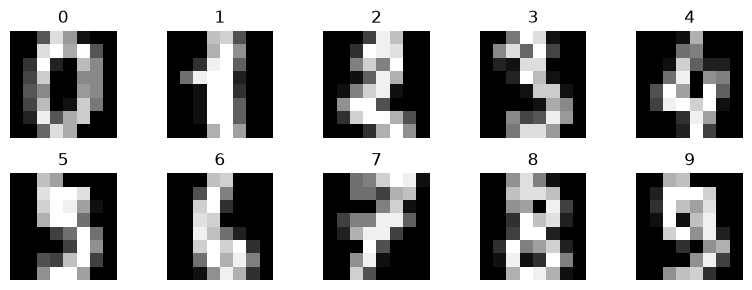

In [2]:
plt.figure(figsize=(8,3))
for i in range(10):
    plt.subplot(2,5,i+1); plt.imshow(X[i],cmap='gray'); plt.title(str(y[i])); plt.axis('off')
plt.tight_layout(); plt.show()

**Giải thích:** ảnh chỉ 8×8 nên rất nhỏ, thích hợp để demo CNN nhanh.

## 2. CNN from scratch bằng NumPy

In [3]:
def conv2d(image,kernel):
    h,w=image.shape; kh,kw=kernel.shape; out=np.zeros((h-kh+1,w-kw+1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]): out[i,j]=np.sum(image[i:i+kh,j:j+kw]*kernel)
    return out

def relu(x): return np.maximum(0,x)

def max_pool(x,size=2):
    h,w=x.shape; out=np.zeros((h//size,w//size))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]): out[i,j]=np.max(x[i*size:(i+1)*size,j*size:(j+1)*size])
    return out

kernel=np.array([[1,0,-1],[1,0,-1],[1,0,-1]])
img=X_train[0]/16.0; conv=relu(conv2d(img,kernel)); pool=max_pool(conv)
print(img.shape,conv.shape,pool.shape)

(8, 8) (6, 6) (3, 3)


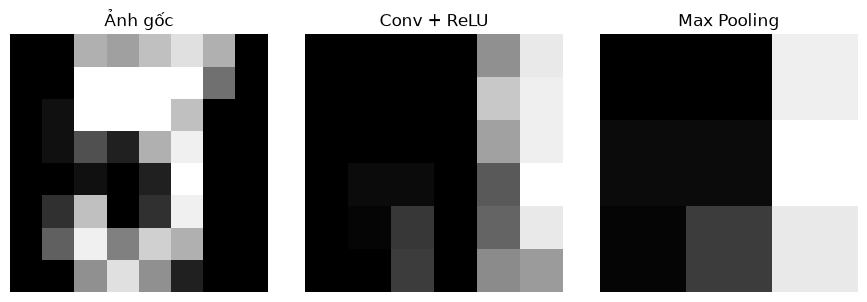

In [4]:
plt.figure(figsize=(9,3))
for k,(im,t) in enumerate([(img,'Ảnh gốc'),(conv,'Conv + ReLU'),(pool,'Max Pooling')]):
    plt.subplot(1,3,k+1); plt.imshow(im,cmap='gray'); plt.title(t); plt.axis('off')
plt.tight_layout(); plt.show()

**Giải thích:** convolution làm nổi bật nét chữ, pooling giảm dữ liệu để tính toán nhanh hơn.

## 3. CNN bằng TensorFlow/Keras

In [5]:
import tensorflow as tf
from tensorflow.keras import layers, models

Xtr=(X_train/16.0).astype('float32')[...,None]
Xte=(X_test/16.0).astype('float32')[...,None]

model=models.Sequential([
    layers.Conv2D(16,3,activation='relu',input_shape=(8,8,1)),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(32,activation='relu'),
    layers.Dense(10,activation='softmax')
])
model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])
history=model.fit(Xtr,y_train,epochs=15,batch_size=32,validation_split=0.1,verbose=1)

C:\Users\Dat\anaconda3\envs\cnn_env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.3016 - loss: 2.1936 - val_accuracy: 0.3889 - val_loss: 2.0821
Epoch 2/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5027 - loss: 1.9037 - val_accuracy: 0.6944 - val_loss: 1.6998
Epoch 3/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7680 - loss: 1.4351 - val_accuracy: 0.7847 - val_loss: 1.1903
Epoch 4/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.8476 - loss: 0.9595 - val_accuracy: 0.8542 - val_loss: 0.8032
Epoch 5/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.8840 - loss: 0.6509 - val_accuracy: 0.8611 - val_loss: 0.5962
Epoch 6/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8971 - loss: 0.4860 - val_accuracy: 0.8889 - val_loss: 0.4504
Epoch 7/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9095 - loss: 0.3945 - val_accuracy: 0.9167 - val_loss: 0.3766
Epoch 8/15
41/41 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9211 - loss: 0.3338 - val_accuracy: 0.9306 - val_

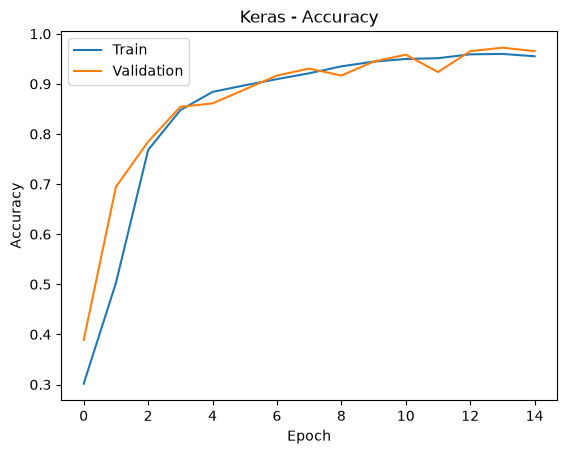

In [6]:
plt.plot(history.history['accuracy'],label='Train'); plt.plot(history.history['val_accuracy'],label='Validation')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Keras - Accuracy'); plt.legend(); plt.show()

**Giải thích:** accuracy tăng thể hiện mô hình học được các nét đặc trưng của chữ số.

Test accuracy: 0.9333333373069763


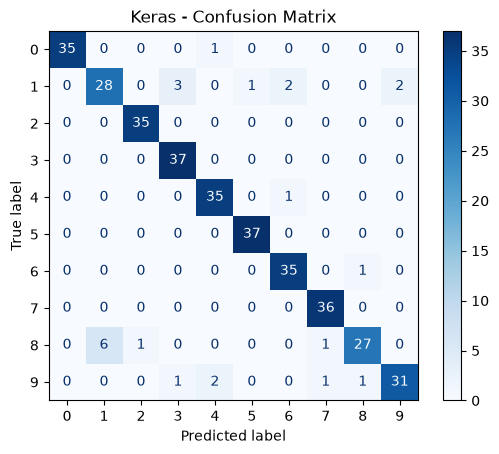

In [7]:
loss,acc=model.evaluate(Xte,y_test,verbose=0); print('Test accuracy:',acc)
y_pred=np.argmax(model.predict(Xte,verbose=0),axis=1)
ConfusionMatrixDisplay(confusion_matrix(y_test,y_pred)).plot(cmap='Blues')
plt.title('Keras - Confusion Matrix'); plt.show()

**Giải thích:** đường chéo chính càng lớn thì mô hình dự đoán càng chính xác.

## 4. CNN bằng PyTorch

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset,DataLoader

device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
Xt=torch.tensor((X_train/16.0)[:,None,:,:],dtype=torch.float32)
yt=torch.tensor(y_train,dtype=torch.long)
loader=DataLoader(TensorDataset(Xt,yt),batch_size=32,shuffle=True)

class DigitCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(1,16,3),nn.ReLU(),nn.MaxPool2d(2),nn.Flatten(),nn.Linear(16*3*3,32),nn.ReLU(),nn.Linear(32,10))
    def forward(self,x): return self.net(x)

torch_model=DigitCNN().to(device)
criterion=nn.CrossEntropyLoss(); optimizer=optim.Adam(torch_model.parameters(),lr=0.001)

In [9]:
accs=[]
for epoch in range(15):
    correct=total=0; torch_model.train()
    for xb,yb in loader:
        xb,yb=xb.to(device),yb.to(device)
        optimizer.zero_grad(); out=torch_model(xb); loss=criterion(out,yb)
        loss.backward(); optimizer.step()
        pred=out.argmax(1); correct+=(pred==yb).sum().item(); total+=yb.size(0)
    acc=correct/total; accs.append(acc); print(f'Epoch {epoch+1}: {acc:.4f}')

Epoch 1: 0.2143
Epoch 2: 0.5727
Epoch 3: 0.7829
Epoch 4: 0.8622
Epoch 5: 0.8852
Epoch 6: 0.9193
Epoch 7: 0.9255
Epoch 8: 0.9297
Epoch 9: 0.9395
Epoch 10: 0.9436
Epoch 11: 0.9499
Epoch 12: 0.9548
Epoch 13: 0.9548
Epoch 14: 0.9582
Epoch 15: 0.9631


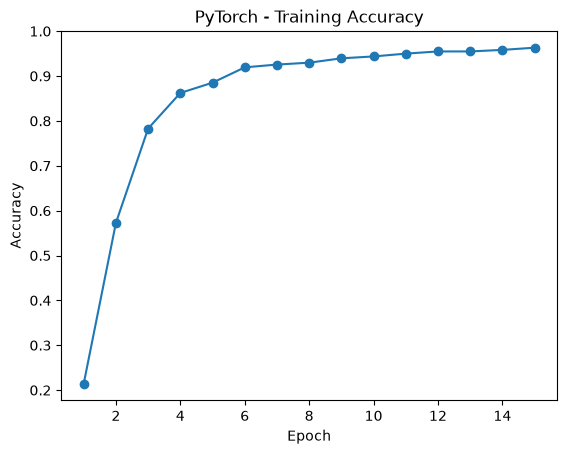

In [10]:
plt.plot(range(1,16),accs,marker='o'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('PyTorch - Training Accuracy'); plt.show()

**Giải thích:** đường accuracy đi lên cho thấy mô hình cải thiện qua các epoch.

TensorFlow/Keras: 0.9333
PyTorch         : 0.9444


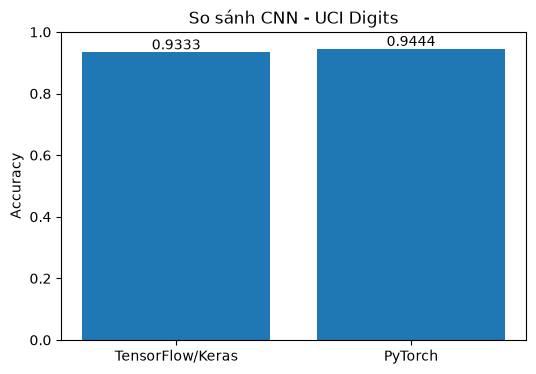

In [12]:
# ===== SO SÁNH TENSORFLOW/KERAS VÀ PYTORCH =====

# 1. Accuracy của TensorFlow/Keras
_, keras_acc = model.evaluate(Xte, y_test, verbose=0)

# 2. Chuyển tập test sang Tensor cho PyTorch
Xte_t = torch.tensor(
    Xte.transpose(0, 3, 1, 2),
    dtype=torch.float32
)

yte_t = torch.tensor(
    y_test,
    dtype=torch.long
)

test_loader = DataLoader(
    TensorDataset(Xte_t, yte_t),
    batch_size=64,
    shuffle=False
)

# 3. Accuracy của PyTorch
torch_model.eval()

correct = 0
total = 0

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        output = torch_model(xb)
        pred = output.argmax(1)

        correct += (pred == yb).sum().item()
        total += yb.size(0)

pytorch_acc = correct / total

# 4. In kết quả
print(f"TensorFlow/Keras: {keras_acc:.4f}")
print(f"PyTorch         : {pytorch_acc:.4f}")

# 5. Vẽ biểu đồ
methods = ["TensorFlow/Keras", "PyTorch"]
accuracy = [keras_acc, pytorch_acc]

plt.figure(figsize=(6, 4))
bars = plt.bar(methods, accuracy)

plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("So sánh CNN - UCI Digits")

for bar, value in zip(bars, accuracy):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.show()

Biểu đồ so sánh Accuracy trên tập test của CNN được xây dựng bằng TensorFlow/Keras và PyTorch.

- UCI Digits có ảnh kích thước nhỏ **8×8**, nên CNN sử dụng kiến trúc khá đơn giản.
- TensorFlow/Keras giúp xây dựng mô hình nhanh với ít dòng code.
- PyTorch cho phép kiểm soát chi tiết quá trình huấn luyện.
- Accuracy của hai mô hình có thể chênh lệch nhẹ do khởi tạo trọng số và quá trình tối ưu ngẫu nhiên.
- CNN from scratch chỉ minh họa các phép toán cơ bản nên không đưa vào biểu đồ Accuracy.

## 5. Giải thích các hàm chính
- `load_digits()`: tải dataset chữ số.
- `train_test_split()`: chia train/test.
- `Conv2D/Conv2d`: trích xuất đặc trưng.
- `ReLU`: loại giá trị âm.
- `MaxPooling`: giảm kích thước feature map.
- `Flatten`: chuyển dữ liệu thành vector.
- `Dense/Linear`: phân loại.
- `Adam`: tối ưu trọng số.
- `CrossEntropyLoss`: hàm mất mát phân loại.
- `backward()`: tính gradient.
- `optimizer.step()`: cập nhật trọng số.